<a href="https://colab.research.google.com/github/NgoNgoc05-tech/DNU_FIT4007_CNPM_Nhom10/blob/main/BTL_DeTai_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài tập lớn Nhập môn Học máy – Đề tài 6: Chẩn đoán viêm phổi qua ảnh X-quang
**Dataset:** Chest X-Ray Images (Pneumonia) – Kaggle (Paul Mooney)

**Cách chạy trên Colab**
1. **Bản nhẹ cho CPU:** `Thời gian chạy → Thay đổi loại thời gian chạy → CPU` (có GPU thì càng nhanh). Đã đặt sẵn `AUG_COPIES = 0` và chỉ dùng ResNet50 cho Transfer Learning; nếu có GPU, đặt `AUG_COPIES = 1` và thêm `'EfficientNet-B0'`, `'DenseNet121'` vào `DEEP_NAMES`
2. Chạy lần lượt từ trên xuống dưới (Runtime → Run all).

**Ánh xạ với cấu trúc báo cáo**
| Cell / Mục | Phần báo cáo |
|---|---|
| 1. EDA | 1. Đặt vấn đề & phân tích dữ liệu |
| 2. Tiền xử lý, 3. Trích xuất đặc trưng, 4. Huấn luyện | 2. Thiết kế giải pháp & quy trình |
| 5. Đánh giá | 4. Thử nghiệm & kết quả |
| 6. Lưu mô hình & GUI | Điểm thưởng GUI |

**So sánh hai hướng đặc trưng:** (A) cổ điển: HOG, HOG+LBP+Histogram; (B) Transfer Learning: ResNet50, DenseNet121, EfficientNet-B0 (pretrained ImageNet, lấy vector trước lớp phân loại).

In [ ]:
!pip -q install kagglehub gradio scikit-image

In [ ]:
import os, glob, time, random, json, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from joblib import Parallel, delayed, dump

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, ConfusionMatrixDisplay)
from skimage.feature import hog, local_binary_pattern

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision import models

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

CLASS_NAMES = ['NORMAL', 'PNEUMONIA']   # 0 = bình thường, 1 = viêm phổi
IMG_BASE = 256     # kích thước ảnh gốc sau khi cache (xám)
IMG_HOG  = 128     # kích thước cho HOG
IMG_DEEP = 224     # kích thước cho CNN pretrained
AUG_COPIES = 0     # số bản sao tăng cường dữ liệu cho tập train
sns.set_theme(style='whitegrid')

Device: cpu


In [ ]:
# ===== Tải dataset từ Kaggle (kagglehub) =====
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print('Downloaded to:', path)

# Phương án dự phòng nếu kagglehub lỗi (cần file kaggle.json):
# from google.colab import files; files.upload()          # upload kaggle.json
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/data --unzip
# path = '/content/data'

ROOT = None
for r, dirs, _ in os.walk(path):
    if {'train', 'test'}.issubset(set(dirs)) and '__MACOSX' not in r:
        ROOT = r; break
print('ROOT =', ROOT, '->', os.listdir(ROOT))

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded to: /kaggle/input/chest-xray-pneumonia
ROOT = /kaggle/input/chest-xray-pneumonia/chest_xray -> ['chest_xray', '__MACOSX', 'val', 'test', 'train']


## 1. Khám phá dữ liệu (EDA)

In [ ]:
rows = []
for split in ['train', 'val', 'test']:
    for label in CLASS_NAMES:
        for p in glob.glob(f'{ROOT}/{split}/{label}/*'):
            if p.lower().endswith(('.jpeg', '.jpg', '.png')):
                rows.append((p, split, label))
df = pd.DataFrame(rows, columns=['path', 'orig_split', 'label'])
df['y'] = (df.label == 'PNEUMONIA').astype(int)
# Với ảnh viêm phổi, tên file cho biết loại: bacteria / virus
df['subtype'] = np.where(df.label == 'NORMAL', 'normal',
                 np.where(df.path.str.lower().str.contains('bacteria'), 'bacteria', 'virus'))

print('Tổng số ảnh:', len(df))
print('\nCấu trúc thư mục: train/ val/ test/ -> NORMAL/ PNEUMONIA/')
print('\nSố ảnh theo tập gốc và nhãn:')
display(pd.crosstab(df.orig_split, df.label, margins=True))
df.info()

Tổng số ảnh: 5856

Cấu trúc thư mục: train/ val/ test/ -> NORMAL/ PNEUMONIA/

Số ảnh theo tập gốc và nhãn:


label,NORMAL,PNEUMONIA,All
orig_split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5856 entries, 0 to 5855
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   path        5856 non-null   object
 1   orig_split  5856 non-null   object
 2   label       5856 non-null   object
 3   y           5856 non-null   int64 
 4   subtype     5856 non-null   object
dtypes: int64(1), object(4)
memory usage: 228.9+ KB


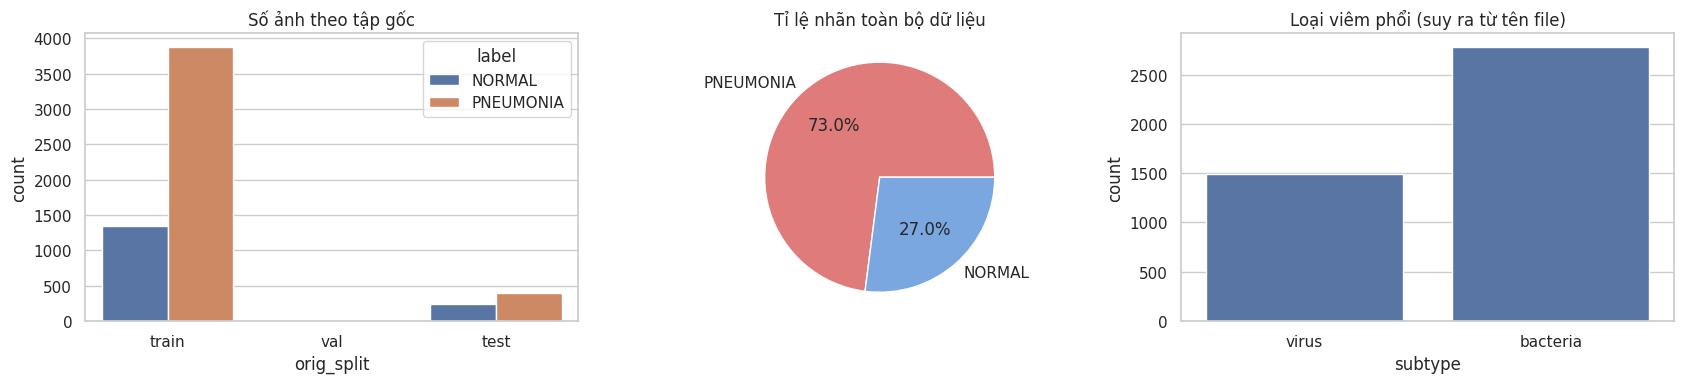

Mất cân bằng lớp (train gốc): PNEUMONIA/NORMAL = 3875/1341 = 2.89
Lưu ý: tập val gốc chỉ có 16 ảnh -> quá nhỏ, sẽ gộp vào train rồi chia lại.


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(data=df, x='orig_split', hue='label', order=['train', 'val', 'test'], ax=ax[0])
ax[0].set_title('Số ảnh theo tập gốc')
df.label.value_counts().plot.pie(autopct='%1.1f%%', ax=ax[1], colors=['#e07b7b', '#7ba7e0'])
ax[1].set_ylabel(''); ax[1].set_title('Tỉ lệ nhãn toàn bộ dữ liệu')
sns.countplot(data=df[df.label == 'PNEUMONIA'], x='subtype', ax=ax[2])
ax[2].set_title('Loại viêm phổi (suy ra từ tên file)')
plt.tight_layout(); plt.show()

tr = df[df.orig_split == 'train']
print(f'Mất cân bằng lớp (train gốc): PNEUMONIA/NORMAL = {(tr.y==1).sum()}/{(tr.y==0).sum()} '
      f'= {(tr.y==1).sum()/(tr.y==0).sum():.2f}')
print('Lưu ý: tập val gốc chỉ có', (df.orig_split=="val").sum(), 'ảnh -> quá nhỏ, sẽ gộp vào train rồi chia lại.')

  0%|          | 0/5856 [00:00<?, ?it/s]

Thống kê kích thước ảnh:


,width,height
count,5856.0,5856.0
mean,1327.9,970.7
std,363.5,383.4
min,384.0,127.0
25%,1056.0,688.0
50%,1281.0,888.0
75%,1560.0,1187.0
max,2916.0,2713.0


Số kênh màu / chế độ ảnh:


,mode,channels,count
0,L,1,5573
1,RGB,3,283


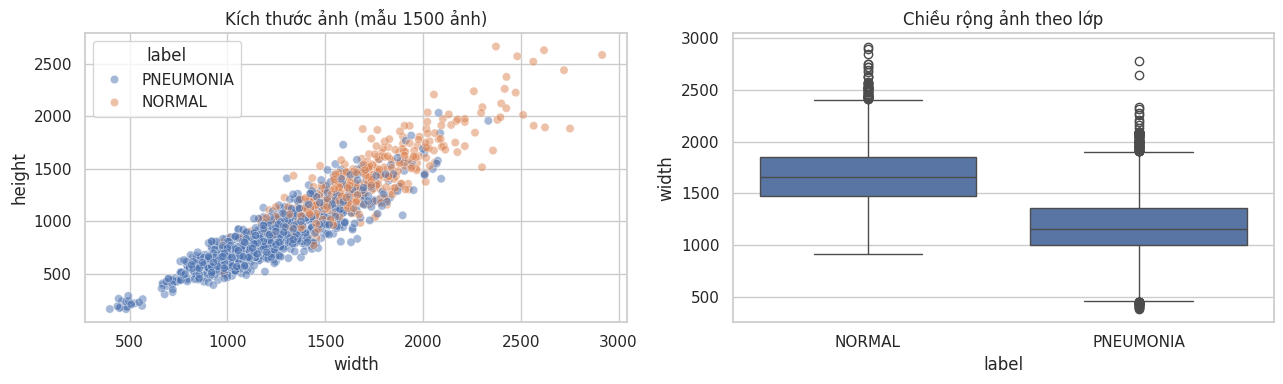

In [ ]:
def get_info(p):
    with Image.open(p) as im:
        return im.size[0], im.size[1], len(im.getbands()), im.mode
info = [get_info(p) for p in tqdm(df.path)]
df[['width', 'height', 'channels', 'mode']] = pd.DataFrame(info, index=df.index)

print('Thống kê kích thước ảnh:')
display(df[['width', 'height']].describe().round(1))
print('Số kênh màu / chế độ ảnh:'); display(df.groupby(['mode', 'channels']).size().rename('count').reset_index())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df.sample(1500, random_state=SEED), x='width', y='height', hue='label', alpha=.5, ax=ax[0])
ax[0].set_title('Kích thước ảnh (mẫu 1500 ảnh)')
sns.boxplot(data=df, x='label', y='width', ax=ax[1]); ax[1].set_title('Chiều rộng ảnh theo lớp')
plt.tight_layout(); plt.show()

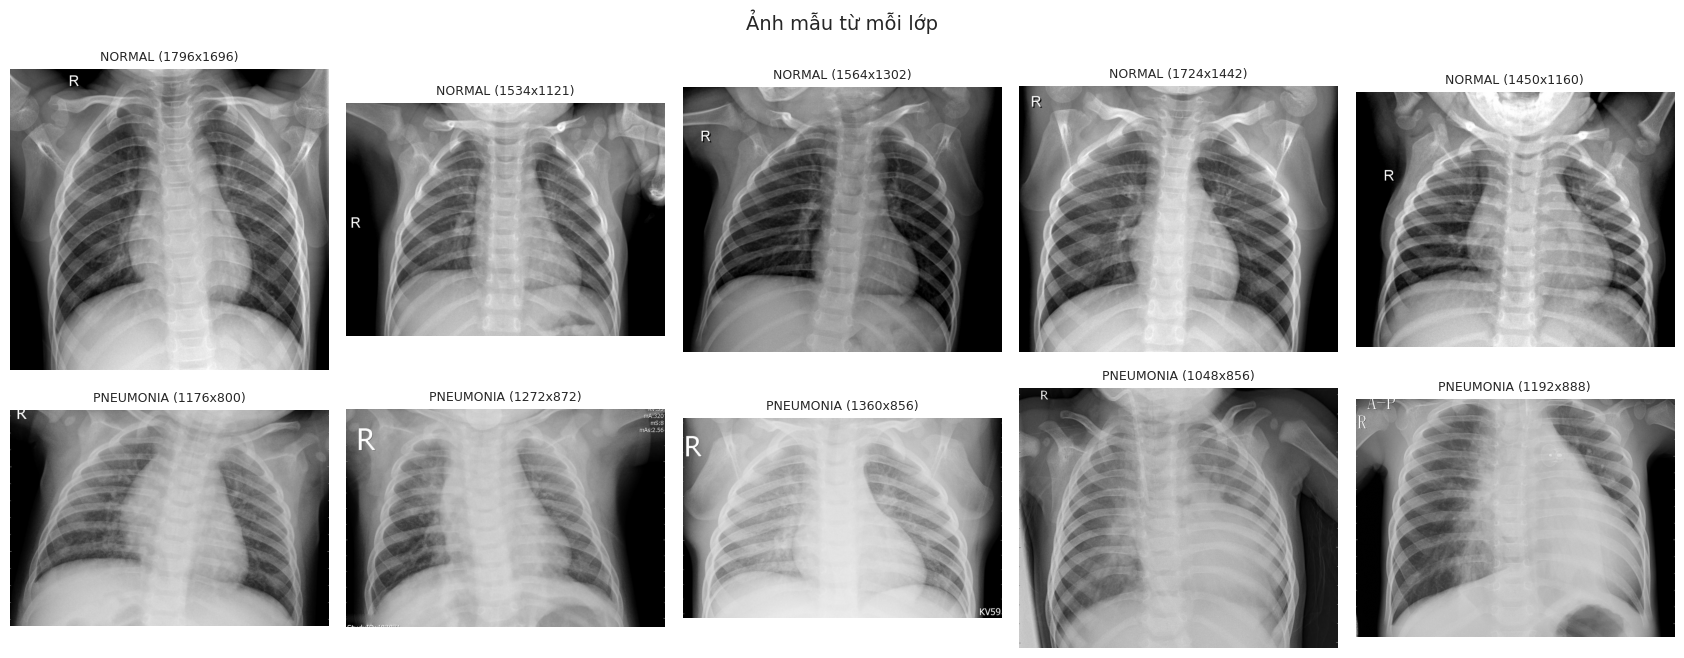

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for i, lab in enumerate(CLASS_NAMES):
    smp = df[df.label == lab].sample(5, random_state=SEED)
    for j, (_, r) in enumerate(smp.iterrows()):
        axes[i, j].imshow(Image.open(r.path).convert('L'), cmap='gray')
        axes[i, j].set_title(f'{lab} ({r.width}x{r.height})', fontsize=9); axes[i, j].axis('off')
plt.suptitle('Ảnh mẫu từ mỗi lớp', fontsize=14); plt.tight_layout(); plt.show()

## 2. Tiền xử lý ảnh
- Chuyển ảnh xám (X-quang vốn không mang thông tin màu), resize đồng nhất, chuẩn hoá pixel về [0, 1].
- Gộp train + val gốc rồi chia lại **80/20 có phân tầng (stratified)**; giữ nguyên tập test gốc (624 ảnh) để đánh giá cuối.
- Tăng cường dữ liệu chỉ áp dụng cho **train** (xoay nhẹ, crop ngẫu nhiên, đổi độ sáng/tương phản). Không lật ngang vì lật làm sai vị trí tim, không thực tế về mặt y khoa.

Train/Val/Test = 4185 1047 624
  train: PNEUMONIA=74.2%  NORMAL=25.8%
  val: PNEUMONIA=74.2%  NORMAL=25.8%
  test: PNEUMONIA=62.5%  NORMAL=37.5%
Cache ảnh: (5856, 256, 256) (70s)


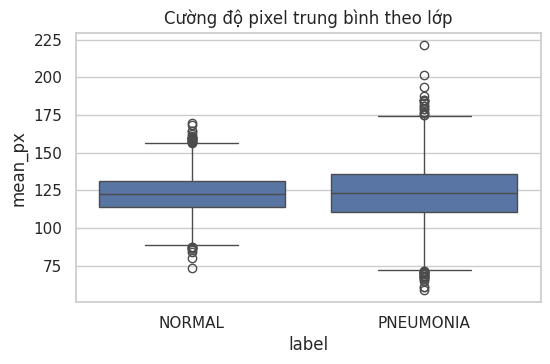

In [ ]:
dev = df[df.orig_split != 'test']
train_df, val_df = train_test_split(dev, test_size=0.2, stratify=dev.y, random_state=SEED)
test_df = df[df.orig_split == 'test']
print('Train/Val/Test =', len(train_df), len(val_df), len(test_df))
for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'  {n}: PNEUMONIA={d.y.mean():.1%}  NORMAL={1-d.y.mean():.1%}')

# Cache toàn bộ ảnh: xám + resize 256x256 (uint8) để các bước sau chạy nhanh
def load_resized(p):
    return np.asarray(Image.open(p).convert('L').resize((IMG_BASE, IMG_BASE), Image.BILINEAR), dtype=np.uint8)
t = time.time()
IMGS = np.stack(Parallel(n_jobs=-1)(delayed(load_resized)(p) for p in df.path))
print('Cache ảnh:', IMGS.shape, f'({time.time()-t:.0f}s)')

Xtr_img, ytr = IMGS[train_df.index.values], train_df.y.values
Xva_img, yva = IMGS[val_df.index.values],   val_df.y.values
Xte_img, yte = IMGS[test_df.index.values],  test_df.y.values

# Độ sáng trung bình theo lớp
df['mean_px'] = IMGS.reshape(len(df), -1).mean(1)
plt.figure(figsize=(6, 3.5)); sns.boxplot(data=df, x='label', y='mean_px')
plt.title('Cường độ pixel trung bình theo lớp'); plt.show()

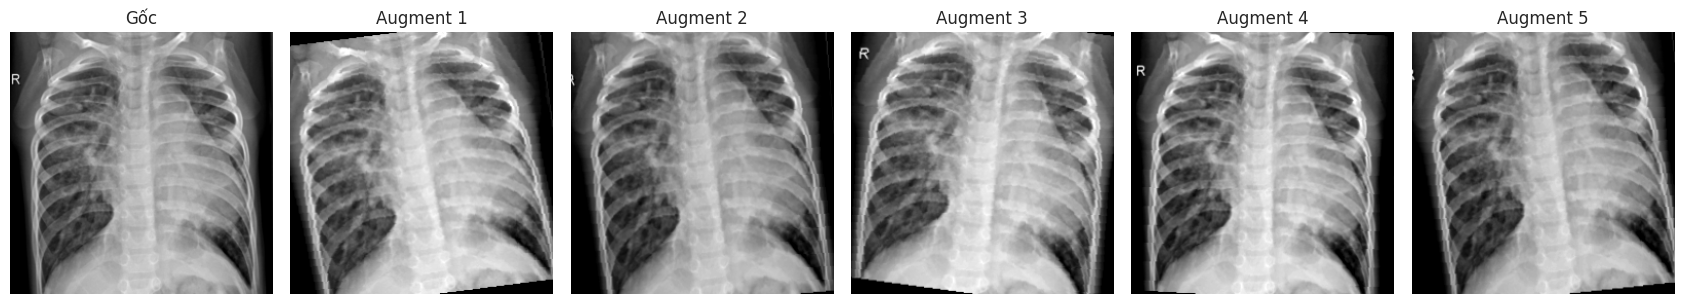

In [ ]:
aug_tf = T.Compose([
    T.RandomRotation(10, fill=0),
    T.RandomResizedCrop(IMG_BASE, scale=(0.85, 1.0), ratio=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
])
def augment_fn(a):
    return np.asarray(aug_tf(Image.fromarray(a)), dtype=np.uint8)

# Minh hoạ augmentation
a0 = Xtr_img[0]
fig, ax = plt.subplots(1, 6, figsize=(17, 3))
ax[0].imshow(a0, cmap='gray'); ax[0].set_title('Gốc'); ax[0].axis('off')
for i in range(1, 6):
    ax[i].imshow(augment_fn(a0), cmap='gray'); ax[i].set_title(f'Augment {i}'); ax[i].axis('off')
plt.tight_layout(); plt.show()

## 3. Trích xuất đặc trưng
### Hướng A – Phương pháp cổ điển
- **HOG** (9 hướng, ô 16×16, block 2×2, ảnh 128×128 → 1764 chiều): nắm bắt cạnh/hình dạng cấu trúc phổi.
- **LBP uniform** (kết cấu, 10 chiều) + **histogram cường độ** (32 bin) + mean/std: nắm bắt vùng mờ đục (opacity) do viêm phổi.

### Hướng B – Transfer Learning
CNN pretrained ImageNet, bỏ lớp phân loại cuối, lấy vector đặc trưng pooled: ResNet50 (2048-d), DenseNet121 (1024-d), EfficientNet-B0 (1280-d).

In [ ]:
def classical_one(a):
    g = np.asarray(Image.fromarray(a).resize((IMG_HOG, IMG_HOG), Image.BILINEAR))
    h = hog(g / 255., orientations=9, pixels_per_cell=(16, 16),
            cells_per_block=(2, 2), block_norm='L2-Hys')
    lbp = local_binary_pattern(g, P=8, R=1, method='uniform')
    lbp_h = np.histogram(lbp, bins=np.arange(11), density=True)[0]
    hist = np.histogram(g, bins=32, range=(0, 256), density=True)[0] * 32
    extra = np.concatenate([lbp_h, hist, [g.mean() / 255., g.std() / 255.]])
    return h.astype(np.float32), extra.astype(np.float32)

def run_classical(arrs, augment=False):
    H, E = [], []
    for a in tqdm(arrs, leave=False):
        h, e = classical_one(augment_fn(a) if augment else a)
        H.append(h); E.append(e)
    return np.array(H), np.array(E)

random.seed(SEED); torch.manual_seed(SEED)
t = time.time()
parts = [run_classical(Xtr_img)] + [run_classical(Xtr_img, True) for _ in range(AUG_COPIES)]
Htr = np.vstack([p[0] for p in parts]); Etr = np.vstack([p[1] for p in parts])
Hva, Eva = run_classical(Xva_img); Hte, Ete = run_classical(Xte_img)
Y_TRAIN = np.concatenate([ytr] * (1 + AUG_COPIES))   # thứ tự: bản gốc rồi các bản augment

FEATS = {
    'HOG':          {'train': Htr, 'val': Hva, 'test': Hte},
    'HOG+LBP+Hist': {'train': np.hstack([Htr, Etr]), 'val': np.hstack([Hva, Eva]), 'test': np.hstack([Hte, Ete])},
}
print(f'Đặc trưng cổ điển xong ({time.time()-t:.0f}s):', {k: v['train'].shape for k, v in FEATS.items()})

  0%|          | 0/4185 [00:00<?, ?it/s]

  0%|          | 0/1047 [00:00<?, ?it/s]

  0%|          | 0/624 [00:00<?, ?it/s]

Đặc trưng cổ điển xong (56s): {'HOG': (4185, 1764), 'HOG+LBP+Hist': (4185, 1808)}


In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def prep_tensor(a):
    # xám 256 -> 224, [0,1], nhân 3 kênh, chuẩn hoá theo ImageNet
    im = Image.fromarray(a).resize((IMG_DEEP, IMG_DEEP), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(im, dtype=np.float32) / 255.).unsqueeze(0).repeat(3, 1, 1)
    return (x - MEAN) / STD

class XrayDS(Dataset):
    def __init__(self, arrs, augment=False): self.arrs, self.augment = arrs, augment
    def __len__(self): return len(self.arrs)
    def __getitem__(self, i):
        a = self.arrs[i]
        return prep_tensor(augment_fn(a) if self.augment else a)

def get_backbone(name):
    if name == 'ResNet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2); m.fc = nn.Identity()
    elif name == 'DenseNet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
    elif name == 'EfficientNet-B0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
    return m.eval().to(device)

@torch.no_grad()
def extract_deep(model, arrs, augment=False, bs=64):
    dl = DataLoader(XrayDS(arrs, augment), batch_size=bs, num_workers=2)
    out = []
    for x in tqdm(dl, leave=False):
        with torch.autocast(device_type='cuda', enabled=(device == 'cuda')):
            f = model(x.to(device))
        out.append(f.float().cpu().numpy())
    return np.vstack(out)

DEEP_NAMES = ['ResNet50']   # bản nhẹ cho CPU; thêm 'EfficientNet-B0', 'DenseNet121' nếu có GPU
BACKBONES = {}
for name in DEEP_NAMES:
    t = time.time(); torch.manual_seed(SEED)
    m = get_backbone(name); BACKBONES[name] = m
    parts = [extract_deep(m, Xtr_img)] + [extract_deep(m, Xtr_img, True) for _ in range(AUG_COPIES)]
    FEATS[name] = {'train': np.vstack(parts),
                   'val': extract_deep(m, Xva_img), 'test': extract_deep(m, Xte_img)}
    print(f'{name}: train {FEATS[name]["train"].shape} ({time.time()-t:.0f}s)')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 100MB/s]


  0%|          | 0/66 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

ResNet50: train (4185, 2048) (1554s)


## 4. Huấn luyện mô hình
Mỗi bộ đặc trưng được huấn luyện với: Logistic Regression, SVM (RBF), Random Forest. Với đặc trưng CNN có thêm **MLP head** (lớp phân loại mới gắn vào sau backbone đóng băng). Dùng `class_weight='balanced'` để xử lý mất cân bằng lớp, và `StandardScaler` trong pipeline.

In [ ]:
class MLPHead(BaseEstimator, ClassifierMixin):
    # Lớp phân loại mới (Dropout-Linear-ReLU-Dropout-Linear) huấn luyện trên đặc trưng của backbone đóng băng
    def __init__(self, hidden=256, epochs=25, lr=1e-3, wd=1e-3, bs=128, seed=42):
        self.hidden, self.epochs, self.lr, self.wd, self.bs, self.seed = hidden, epochs, lr, wd, bs, seed
    def fit(self, X, y):
        torch.manual_seed(self.seed)
        X = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.float32)
        self.classes_ = np.array([0, 1])
        self.net_ = nn.Sequential(nn.Dropout(0.3), nn.Linear(X.shape[1], self.hidden), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(self.hidden, 1)).to(device)
        pw = torch.tensor((y == 0).sum() / (y == 1).sum(), dtype=torch.float32, device=device)
        crit = nn.BCEWithLogitsLoss(pos_weight=pw)
        opt = torch.optim.AdamW(self.net_.parameters(), lr=self.lr, weight_decay=self.wd)
        n = len(X)
        for _ in range(self.epochs):
            self.net_.train(); perm = torch.randperm(n)
            for i in range(0, n, self.bs):
                idx = perm[i:i + self.bs]
                opt.zero_grad()
                loss = crit(self.net_(X[idx].to(device)).squeeze(1), yt[idx].to(device))
                loss.backward(); opt.step()
        return self
    def decision_function(self, X):
        self.net_.eval()
        with torch.no_grad():
            return self.net_(torch.tensor(X, dtype=torch.float32).to(device)).squeeze(1).cpu().numpy()
    def predict(self, X): return (self.decision_function(X) > 0).astype(int)

def make_models(deep=False):
    ms = {
        'LogReg': LogisticRegression(max_iter=1000, class_weight='balanced', C=0.1),
        'SVM-RBF': SVC(kernel='rbf', C=1.0, class_weight='balanced'),
        'RandomForest': RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=SEED),
    }
    if deep: ms['MLP-head'] = MLPHead(seed=SEED)
    return ms

def get_scores(pipe, X):
    return pipe.predict_proba(X)[:, 1] if hasattr(pipe, 'predict_proba') else pipe.decision_function(X)

def metrics(y, pred, score):
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred), specificity=tn / (tn + fp),
                f1=f1_score(y, pred), roc_auc=roc_auc_score(y, score))

rows, STORE = [], {}
for fname, d in FEATS.items():
    for mname, model in make_models(deep=fname in DEEP_NAMES).items():
        pipe = Pipeline([('scaler', StandardScaler()), ('clf', model)])
        t = time.time(); pipe.fit(d['train'], Y_TRAIN); ft = time.time() - t
        for split, y in (('val', yva), ('test', yte)):
            s = get_scores(pipe, d[split]); p = pipe.predict(d[split])
            rows.append(dict(features=fname, model=mname, split=split, n_features=d[split].shape[1],
                             fit_sec=round(ft, 1), **metrics(y, p, s)))
            if split == 'test': STORE[(fname, mname)] = dict(pipe=pipe, score=s, pred=p)
        print(f'{fname:15s} | {mname:13s} | fit {ft:5.1f}s | val F1 = {rows[-2]["f1"]:.4f} | test F1 = {rows[-1]["f1"]:.4f}')
res = pd.DataFrame(rows)

HOG             | LogReg        | fit   1.3s | val F1 = 0.9825 | test F1 = 0.8658
HOG             | SVM-RBF       | fit   6.7s | val F1 = 0.9812 | test F1 = 0.8619
HOG             | RandomForest  | fit  18.0s | val F1 = 0.9764 | test F1 = 0.8244
HOG+LBP+Hist    | LogReg        | fit   1.9s | val F1 = 0.9838 | test F1 = 0.8622
HOG+LBP+Hist    | SVM-RBF       | fit   6.8s | val F1 = 0.9832 | test F1 = 0.8603
HOG+LBP+Hist    | RandomForest  | fit  18.4s | val F1 = 0.9776 | test F1 = 0.8234
ResNet50        | LogReg        | fit   1.2s | val F1 = 0.9800 | test F1 = 0.8636
ResNet50        | SVM-RBF       | fit   9.9s | val F1 = 0.9773 | test F1 = 0.8649
ResNet50        | RandomForest  | fit  16.1s | val F1 = 0.9557 | test F1 = 0.8268
ResNet50        | MLP-head      | fit  13.0s | val F1 = 0.9780 | test F1 = 0.8689


## 5. Đánh giá và so sánh
Mô hình tốt nhất được **chọn theo F1 trên tập validation** (không nhìn vào test để chọn), rồi báo cáo kết quả trên test. Với y khoa, **Recall** (không bỏ sót ca bệnh) và **Specificity** đặc biệt quan trọng.

In [ ]:
val_res  = res[res.split == 'val'].set_index(['features', 'model'])
test_res = res[res.split == 'test'].set_index(['features', 'model'])

print('=== KẾT QUẢ TRÊN TẬP TEST (sắp xếp theo F1) ===')
cols = ['n_features', 'fit_sec', 'accuracy', 'precision', 'recall', 'specificity', 'f1', 'roc_auc']
display(test_res[cols].sort_values('f1', ascending=False).style.format(precision=4).background_gradient(
        subset=['accuracy', 'precision', 'recall', 'specificity', 'f1', 'roc_auc'], cmap='Greens'))

best_by_feat = {f: val_res.loc[f]['f1'].idxmax() for f in FEATS}          # mô hình tốt nhất cho từng bộ đặc trưng (theo val F1)
best_key = val_res['f1'].idxmax()                                          # (features, model) tốt nhất tổng thể
print('\nMô hình tốt nhất theo val F1:', best_key)
print('Kết quả test của mô hình đó:'); display(test_res.loc[[best_key], cols].round(4))

# Bảng tóm tắt: mô hình tốt nhất của mỗi bộ đặc trưng
summary = pd.DataFrame({f: test_res.loc[(f, m), cols] for f, m in best_by_feat.items()}).T
summary.insert(0, 'best_model', [best_by_feat[f] for f in summary.index])
print('\n=== Tóm tắt: mô hình tốt nhất của từng bộ đặc trưng (test) ===')
display(summary.round(4))
res.to_csv('/content/results_all.csv', index=False)

=== KẾT QUẢ TRÊN TẬP TEST (sắp xếp theo F1) ===



Mô hình tốt nhất theo val F1: ('HOG+LBP+Hist', 'LogReg')
Kết quả test của mô hình đó:


,,n_features,fit_sec,accuracy,precision,recall,specificity,f1,roc_auc
features,model,,,,,,,,
HOG+LBP+Hist,LogReg,1808,1.9,0.8013,0.7608,0.9949,0.4786,0.8622,0.9519



=== Tóm tắt: mô hình tốt nhất của từng bộ đặc trưng (test) ===


,best_model,n_features,fit_sec,accuracy,precision,recall,specificity,f1,roc_auc
HOG,LogReg,1764.0,1.3,0.8077,0.7679,0.9923,0.5000,0.8658,0.9470
HOG+LBP+Hist,LogReg,1808.0,1.9,0.8013,0.7608,0.9949,0.4786,0.8622,0.9519
ResNet50,LogReg,2048.0,1.2,0.8061,0.7706,0.9821,0.5128,0.8636,0.9509


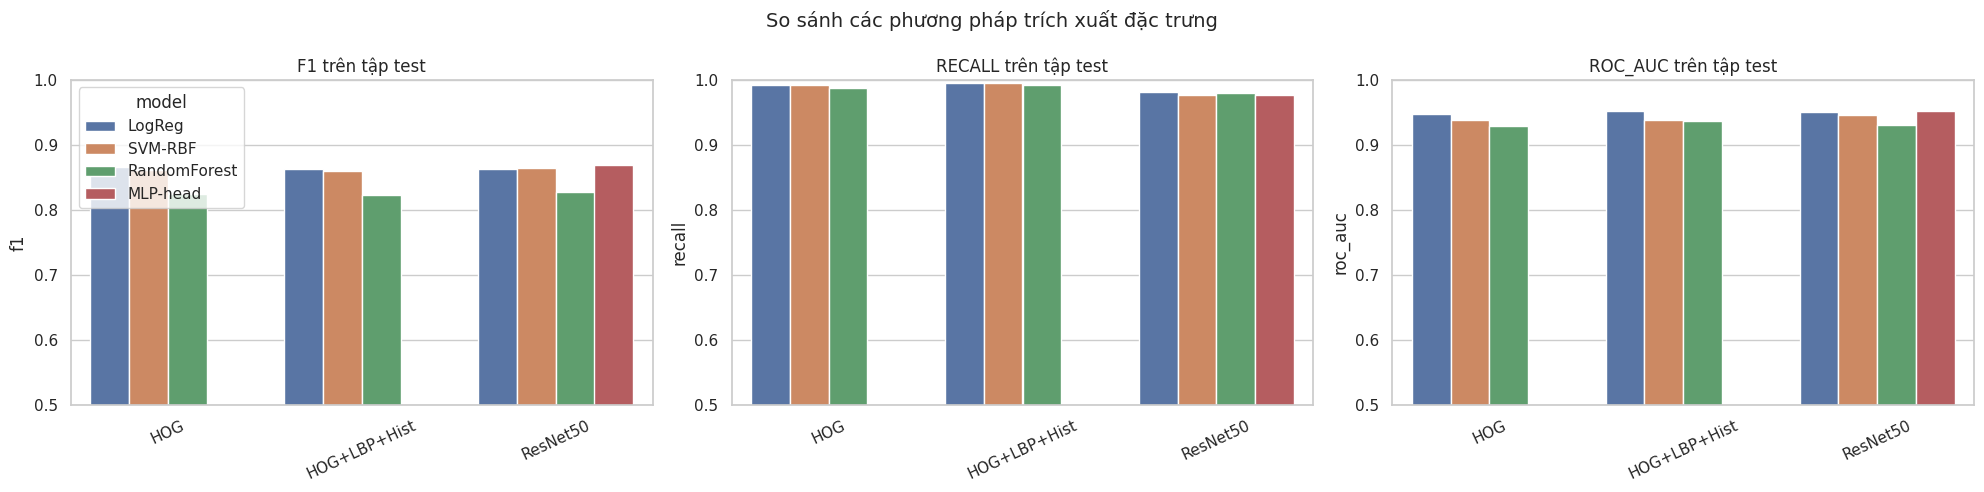

In [ ]:
plot_df = test_res.reset_index()
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, m in zip(ax, ['f1', 'recall', 'roc_auc']):
    sns.barplot(data=plot_df, x='features', y=m, hue='model', ax=a)
    a.set_title(f'{m.upper()} trên tập test'); a.tick_params(axis='x', rotation=25)
    a.set_ylim(0.5, 1.0); a.set_xlabel('')
    if a is not ax[0]: a.get_legend().remove()
plt.suptitle('So sánh các phương pháp trích xuất đặc trưng', fontsize=14); plt.tight_layout(); plt.show()

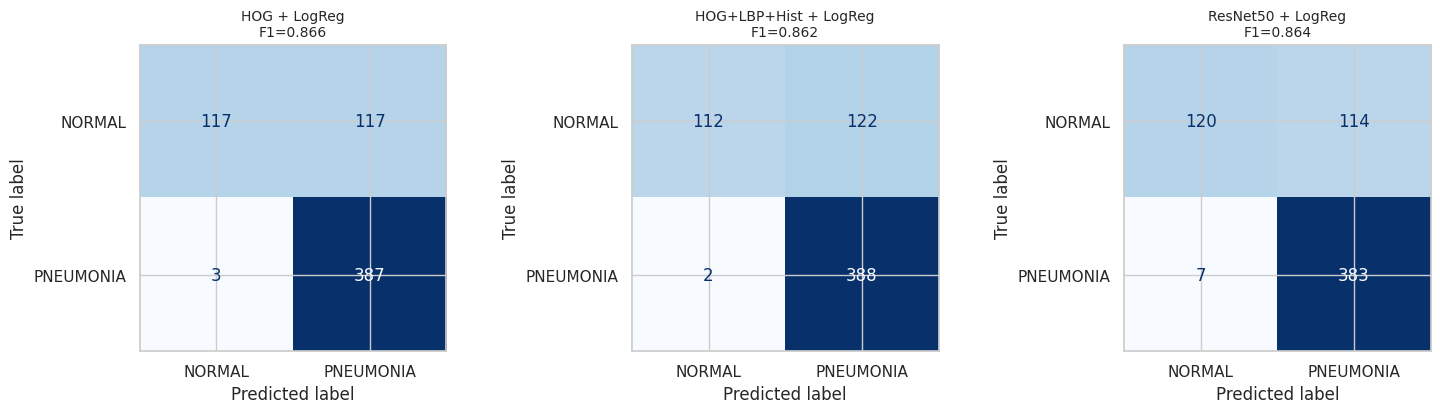

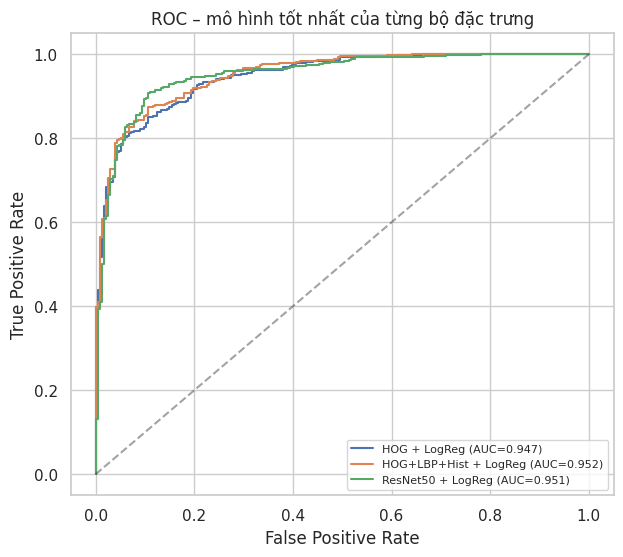

In [ ]:
# Ma trận nhầm lẫn của mô hình tốt nhất cho từng bộ đặc trưng
n = len(FEATS); ncol = 3; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4.3 * nrow)); axes = np.array(axes).ravel()
for ax, (f, m) in zip(axes, best_by_feat.items()):
    ConfusionMatrixDisplay(confusion_matrix(yte, STORE[(f, m)]['pred']), display_labels=CLASS_NAMES).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{f} + {m}\nF1={test_res.loc[(f, m), "f1"]:.3f}', fontsize=10)
for ax in axes[n:]: ax.axis('off')
plt.tight_layout(); plt.show()

# Đường cong ROC
plt.figure(figsize=(7, 6))
for f, m in best_by_feat.items():
    fpr, tpr, _ = roc_curve(yte, STORE[(f, m)]['score'])
    plt.plot(fpr, tpr, label=f'{f} + {m} (AUC={test_res.loc[(f, m), "roc_auc"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=.4); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC – mô hình tốt nhất của từng bộ đặc trưng'); plt.legend(loc='lower right', fontsize=8); plt.show()

Báo cáo chi tiết: HOG+LBP+Hist + LogReg
              precision    recall  f1-score   support

      NORMAL     0.9825    0.4786    0.6437       234
   PNEUMONIA     0.7608    0.9949    0.8622       390

    accuracy                         0.8013       624
   macro avg     0.8716    0.7368    0.7530       624
weighted avg     0.8439    0.8013    0.7803       624

Số ảnh dự đoán sai: 124/624 (FN bỏ sót bệnh = 2, FP báo nhầm = 122)


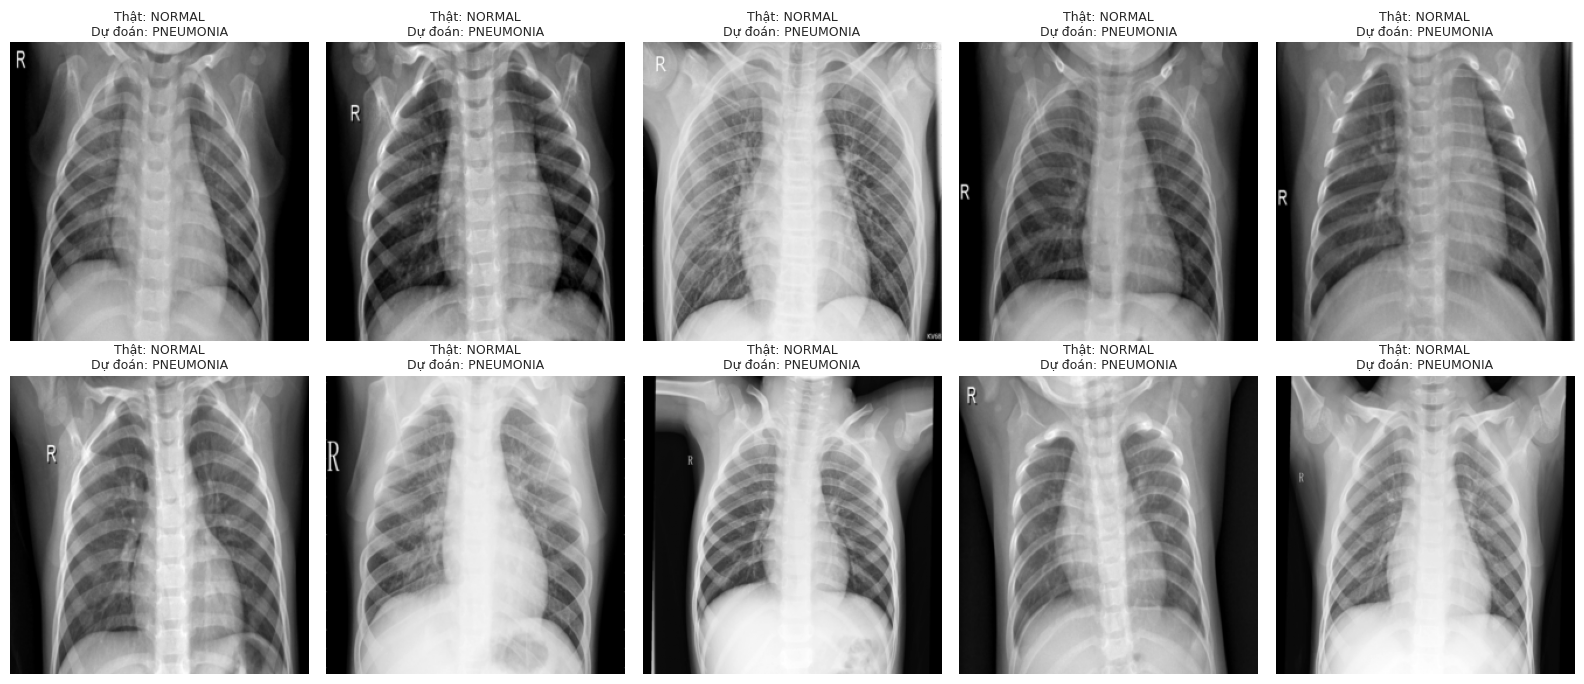

In [ ]:
bf, bm = best_key
print(f'Báo cáo chi tiết: {bf} + {bm}')
print(classification_report(yte, STORE[best_key]['pred'], target_names=CLASS_NAMES, digits=4))

# Phân tích lỗi: hiển thị một số ảnh bị dự đoán sai
wrong = np.where(STORE[best_key]['pred'] != yte)[0]
print(f'Số ảnh dự đoán sai: {len(wrong)}/{len(yte)} '
      f'(FN bỏ sót bệnh = {((yte==1)&(STORE[best_key]["pred"]==0)).sum()}, '
      f'FP báo nhầm = {((yte==0)&(STORE[best_key]["pred"]==1)).sum()})')
show = wrong[:10]
fig, axes = plt.subplots(2, 5, figsize=(16, 7)); axes = axes.ravel()
for ax, i in zip(axes, show):
    ax.imshow(Xte_img[i], cmap='gray'); ax.axis('off')
    ax.set_title(f'Thật: {CLASS_NAMES[yte[i]]}\nDự đoán: {CLASS_NAMES[STORE[best_key]["pred"][i]]}', fontsize=9)
for ax in axes[len(show):]: ax.axis('off')
plt.tight_layout(); plt.show()

## 6. Lưu mô hình và xây dựng GUI (điểm thưởng)

In [ ]:
best_pipe = STORE[best_key]['pipe']
dump(best_pipe, '/content/best_classifier.joblib')
json.dump({'features': bf, 'model': bm, 'test_metrics': test_res.loc[best_key, cols].to_dict()},
          open('/content/best_meta.json', 'w'), indent=2, default=float)
print('Đã lưu: best_classifier.joblib, best_meta.json, results_all.csv')
# from google.colab import files; files.download('/content/best_classifier.joblib')

Đã lưu: best_classifier.joblib, best_meta.json, results_all.csv


In [ ]:
import gradio as gr

def extract_single(fname, a):
    if fname == 'HOG':
        return classical_one(a)[0][None]
    if fname == 'HOG+LBP+Hist':
        h, e = classical_one(a); return np.concatenate([h, e])[None]
    m = BACKBONES[fname]
    with torch.no_grad():
        return m(prep_tensor(a).unsqueeze(0).to(device)).float().cpu().numpy()

def gradio_predict(img):
    if img is None: return None
    a = np.asarray(Image.fromarray(img).convert('L').resize((IMG_BASE, IMG_BASE), Image.BILINEAR), dtype=np.uint8)
    x = extract_single(bf, a)
    if hasattr(best_pipe, 'predict_proba'):
        p = float(best_pipe.predict_proba(x)[0, 1])
    else:
        p = float(1 / (1 + np.exp(-best_pipe.decision_function(x)[0])))
    return {'PNEUMONIA (viêm phổi)': p, 'NORMAL (bình thường)': 1 - p}

demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Image(type='numpy', label='Tải ảnh X-quang ngực'),
    outputs=gr.Label(num_top_classes=2, label='Kết quả dự đoán'),
    title='Chẩn đoán viêm phổi qua ảnh X-quang',
    description=f'Mô hình: {bf} + {bm}. Chỉ phục vụ học tập, không thay thế chẩn đoán của bác sĩ.',
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1e3a4b1a970fb616dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Gợi ý cho phần Thảo luận trong báo cáo
- **Cách chia dữ liệu:** val gốc chỉ 16 ảnh nên gộp vào train rồi chia lại 80/20 có phân tầng. Tập test gốc có phân phối lớp khác train (khoảng 62.5% viêm phổi) nên điểm test có thể thấp hơn val, nên đề cập như một dạng domain shift.
- **Mất cân bằng lớp** (~3:1): xử lý bằng `class_weight='balanced'`, `pos_weight`; đánh giá bằng Recall, Specificity, F1, ROC-AUC chứ không chỉ Accuracy.
- **So sánh A vs B:** HOG/LBP chỉ nắm cạnh và kết cấu cục bộ nên khó phân biệt vùng mờ đục lan toả. CNN pretrained học đặc trưng phân cấp phong phú hơn, dù học trên ảnh tự nhiên (ImageNet). Đối chiếu kết quả bảng/biểu đồ trên để rút ra kết luận.
- **Thách thức:** mất cân bằng lớp, ảnh khác kích thước/độ tương phản, nhãn bacteria/virus khó phân biệt, lệch phân phối train–test, tích hợp mô hình vào GUI (cần giữ nguyên tiền xử lý như lúc huấn luyện).
- **Hướng phát triển:** fine-tune toàn bộ CNN, Grad-CAM để giải thích vùng nghi ngờ, phân loại 3 lớp (normal/bacteria/virus), ensemble nhiều backbone.